<a href="https://colab.research.google.com/github/Mateus-cpa/Analise-bairros-de-Curitiba/blob/main/An%C3%A1lise_imobili%C3%A1ria_em_Curitiba.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importações de bibliotecas

In [63]:
import io
import os

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from google.colab import userdata
import urllib.request



In [73]:
# 1. Preencha apenas seus dados públicos abaixo
USUARIO = "Mateus-cpa"
REPOSITORIO = "Analise-bairros-de-Curitiba"
EMAIL = "mateus.mcpa@gmail.com"
NOME = "Mateus Pinheiro"

# Puxa o token do cofre do Colab automaticamente
TOKEN = userdata.get("GITHUB_TOKEN")

PASTA_REPO = f"/content/"
CAMINHO_ARQUIVO = f"{PASTA_REPO}/imoveis_ativos.csv"

# Ajustar o nome do arquivo para o caminho correto do repositório clonado
PASTA_REPO_NOME = REPOSITORIO

# 1. Clonar o repositório se ele ainda não existir localmente
if not os.path.exists(f'/content/{PASTA_REPO_NOME}'):
    print(f"Clonando o repositório {REPOSITORIO}...")
    # Usando o TOKEN de forma segura na URL de clone
    !git clone https://{TOKEN}@github.com/{USUARIO}/{REPOSITORIO}.git /content/{PASTA_REPO_NOME}
else:
    print("O repositório já está clonado localmente.")

# 2. Salvar os dados atualizados diretamente na pasta do repositório
caminho_csv_repo = f'/content/{PASTA_REPO_NOME}/imoveis_ativos.csv'
anuncios_ativos.to_csv(caminho_csv_repo, index=False)
print(f"✓ Arquivo salvo localmente em: {caminho_csv_repo}")


O repositório já está clonado localmente.
✓ Arquivo salvo localmente em: /content/Analise-bairros-de-Curitiba/imoveis_ativos.csv


#Carga de dados

## Dados do site guru dos imóveis

In [2]:

# Baixar csv
path_guru = 'https://gurudosimoveis.com.br/dados/curitiba-pr.csv'

# Criando uma requisição com User-Agent para evitar o erro 403 Forbidden
req = urllib.request.Request(
    path_guru,
    headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36'}
)

try:
    with urllib.request.urlopen(req) as response:
        csv_data = response.read()
    # Carregando no pandas
    imoveis_df = pandas.read_csv(io.BytesIO(csv_data), header=1)
    display(imoveis_df.sample(10))
except Exception as e:
    print("Erro ao carregar os dados:", e)

imoveis_df.bairro.unique()

,mes,bairro,transacao,mediana_m2,p25_m2,p75_m2,anuncios_ativos_media_dia,novos_anuncios,dias_no_mercado_medio
917,2026-03,Mercês,aluguel,33.0,33.0,34.0,3,2,36.0
24,2025-09,Batel,aluguel,68.0,68.0,68.0,5,2,30.0
1733,2026-09,Hauer,venda,6898.0,6109.0,8103.0,104,7,470.0
1870,2026-10,Guabirotuba,aluguel,30.0,30.0,30.0,7,1,496.0
1775,2026-09,São João,aluguel,82.0,80.0,85.0,4,0,200.0
1597,2026-08,Hugo Lange,aluguel,76.0,76.0,76.0,3,0,75.0
1922,2026-10,Seminário,aluguel,30.0,30.0,30.0,2,0,781.0
1743,2026-09,Juvevê,venda,13663.0,12399.0,15937.0,172,6,554.0
812,2026-02,São Miguel,venda,NaN,NaN,NaN,1,0,102.0
564,2026-01,Alto da Rua XV,aluguel,26.0,26.0,26.0,1,0,226.0


array(['Abranches', 'Água Verde', 'Ahú', 'Alto Boqueirão',
       'Alto da Glória', 'Alto da Rua XV', 'Alto da XV', 'Atuba',
       'Augusta', 'Bacacheri', 'Bairro Alto', 'Bairro Seminário',
       'Barigui', 'Barreirinha', 'Batel', 'Bigorrilho', 'Boa Vista',
       'Bom Retiro', 'Boqueirão', 'Butiatuvinha', 'Cabral', 'Cachoeira',
       'Cajuru', 'Campina do Siqueira', 'Campo Comprido',
       'Campo de Santana', 'Capão da Imbuia', 'Capão Raso', 'Cascatinha',
       'Centro', 'Centro Cívico', 'Champagnat', 'Cidade Industrial',
       'Cidade Industrial de Curitiba', 'Cristo Rei', 'Ecoville', 'Fanny',
       'Fazendinha', 'Ganchinho', 'Guabirotuba', 'Guaíra', 'Hauer',
       'Hugo Lange', 'Jardim Botânico', 'Jardim das Américas',
       'Jardim Social', 'Juvevê', 'Lindóia', 'Mercês', 'Mossunguê',
       'Neoville', 'Novo Mundo', 'Orleans', 'Parolin', 'Pilarzinho',
       'Pinheirinho', 'Portão', 'Prado Velho', 'Rebouças', 'Riviera',
       'Santa Cândida', 'Santa Felicidade', 'Santa Qu

## Tratar bairros com nomes diferentes


In [3]:
imoveis_df['bairro'] = imoveis_df['bairro'].replace({
    'Alto da XV': 'Alto da Rua XV',
    'Alto XV': 'Alto da Rua XV',
    'Ecovile': 'Ecoville',
    'Monssunguê': 'Mossunguê'
})

## Importar csv de anúncios

In [184]:
anuncios_ativos = pd.read_csv('/content/Analise-bairros-de-Curitiba/imoveis_ativos.csv')
display(anuncios_ativos)

,endereco,bairro,tipo,area_casa_m2,area_lote_m2,preco,banheiros,quartos,vagas,idade_anos,link,averbado,descricao
0,"Rua Felisbino Passos, 587",Tingui,Casa,84,184,590000,2,3,2,26.0,https://www.imovelweb.com.br/propriedades/sobr...,Sim,Tem imoveis que se limitam ao que sao. Outros....
1,Rua Hilário Moro,Tingui,Sobrado de condomínio,94,94,499000,2,3,2,NaN,https://www.imovelweb.com.br/propriedades/casa...,Sim,"Localizada no bairro Tingui, esta casa em cond..."
2,"Avenida Monteiro Tourinho, 938",Tingui,Sobrado de condomínio,109,109,599000,2,3,1,15.0,https://www.imovelweb.com.br/propriedades/sobr...,Sim,"Condomínio Siena , são 20 sobrados, residencia..."
3,Rua Mercedes Stresser 379,Bairro Alto,Casa,95,95,580000,1,3,3,14.0,https://www.imovelweb.com.br/propriedades/imov...,Sim,APOLAR VENDE CASA NO BAIRRO ALTO EM CURITIBA *...
4,Rua Rio Araguari 1042,Bairro Alto,Casa,98,98,370000,3,3,2,21.0,https://www.imovelweb.com.br/propriedades/imov...,Não,Imoveis - no Bairro Alto Apolar vende casa loc...
5,Gastão Luiz Cruls 1479,Bairro Alto,Casa,140,140,520000,2,3,2,46.0,https://www.imovelweb.com.br/propriedades/casa...,Não,"Casa com 3 Quartos, Terraço e Churrasqueira no..."
6,Rua Coronel Wallace Scott Murray 810,Santa Cândida,Casa,120,365,510000,2,3,2,30.0,https://www.imovelweb.com.br/propriedades/casa...,Sim,Casa à venda localizada no bairro Santa Cândid...
7,Rua Rei David 323,Santa Cândida,Casa,90,90,475000,2,3,2,NaN,https://www.imovelweb.com.br/propriedades/casa...,Sim,Casa térrea encantadora com 90m² no Santa Când...
8,"Rua David Geronasso, 543",Boa Vista,Casa,70,70,598000,2,3,4,30.0,https://www.imovelweb.com.br/propriedades/casa...,Não,"Casa à venda no bairro Boa Vista, BEM PRÓXIMO ..."


In [259]:
# @title 📋 Cadastro de Novo Anúncio { run: "auto" }

# @markdown Preencha as informações do imóvel abaixo para adicioná-lo ao DataFrame:

endereco = "Rua Coronel Benedito Tertuliano Cordeiro" #@param {type:"string"}
bairro = "Tingui" #@param ['Abranches', 'Água Verde', 'Ahú', 'Alto Boqueirão', 'Alto da Glória', 'Alto da Rua XV', 'Atuba', 'Augusta', 'Bacacheri', 'Bairro Alto', 'Barigui', 'Barreirinha', 'Batel', 'Bigorrilho', 'Boa Vista', 'Bom Retiro', 'Boqueirão', 'Butiatuvinha', 'Cabral', 'Cachoeira', 'Cajuru', 'Campina do Siqueira', 'Campo Comprido', 'Campo de Santana', 'Capão da Imbuia', 'Capão Raso', 'Cascatinha', 'Centro', 'Centro Cívico', 'Cidade Industrial', 'Cristo Rei', 'Ecoville', 'Fanny', 'Fazendinha', 'Ganchinho', 'Guabirotuba', 'Guaíra', 'Hauer', 'Hugo Lange', 'Jardim Botânico', 'Jardim das Américas', 'Jardim Social', 'Juvevê', 'Lindóia', 'Mercês', 'Mossunguê', 'Novo Mundo', 'Orleans', 'Parolin', 'Pilarzinho', 'Pinheirinho', 'Portão', 'Prado Velho', 'Rebouças', 'Santa Cândida', 'Santa Felicidade', 'Santa Quitéria', 'Santo Inácio', 'São Braz', 'São Francisco', 'São João', 'São Lourenço', 'São Miguel', 'Seminário', 'Sítio Cercado', 'Taboão', 'Tarumã', 'Tatuquara', 'Tingui', 'Uberaba', 'Umbará', 'Vila Izabel', 'Vista Alegre', 'Xaxim']
tipo = "Sobrado" #@param ['Casa','Sobrado','Casa de condomínio','Sobrado de condomínio','Lote','Chácara']
area_casa_m2 = 137 #@param {type:"integer"}
area_lote_m2 = 152 #@param {type:"integer"}
preco = 609000 #@param {type:"number"}
banheiros = 2 #@param {type:"integer"}
quartos = 3 #@param {type:"integer"}
vagas = 3 #@param {type:"integer"}
idade_anos = None #@param
link = "https://www.zapimoveis.com.br/imovel/venda-sobrados-3-quartos-com-quintal-bacacheri-curitiba-pr-136m2-id-2898487400/?source=ranking%2Crp" #@param {type:"string"}
averbado = "Sim" #@param ["Sim", "Não"]
descricao = "Sobrado à venda no Bacacheri (Tingui) – 136,96 m² | 3 Dormitórios | 3 Vagas | Ótimo Estado! Este excelente sobrado está localizado no coração do bairro Tingui, em uma das regiões mais altas e valorizadas de Curitiba, encostado no tradicional Conjunto Solar.   SOBRADO: Este sobrado tem uma proposta diferenciada: o acesso à área social é feita diretamente pela entrada com escada e rampa e o acesso à cozinha pode ser feita pela entrada da garagem. Isso falicilita eventual necessidade de acesso por pessoa com PNE. Desocupado, contendo: 3 dormitórios sendo uma suíte. Sala espaçosa e bem iluminada. Banheiro social. Cozinha com copa. Lavanderia e espaço externo. Churrasqueira a carvão, coberta, na garagem. 3 vagas de garagem, Armário externo para uso como depósito. Local coberto para armazenamento de botijão de gás, 13k ou P45.  DETALHES: Para a fachada temos 2 sugestões de cores conforme pode ser visto nas fotos 3 e 4. Aquecimento a gás e elétrico (220v). Sistema de alrme. Área construída: 136,96 m² (averbada). Área total do terreno: 152,46 m². IPTU 2026 mensal (10x) = R$ 220,00/mês. Condomínio: não tem. Ano de construção: 2007. Analisa permuta parcial por apartamento somente na região norte e por valor até R$ 250.000,00.  DIFERENCIAIS: Ótimo estado de conservação. Região tranquila, com excelente infraestrutura. Escolas de educação infantil e ensino médio nas proximidades. Fácil acesso a comércios, transporte público e principais vias.  Pontos de referência: Vizinho do Conjunto Solar. Escola Municipal Cerro Azul, pré-escola e fundamental 1. Colégio Estadual Dona Branca, fundamental 2 e ensino médio. Panificadora Roma. Igreja São Pedro e São Paulo. Centro Gastronômico Càdore. Hospital Vita. Ônibus Linha 213 - 1 quadra. Ônibus várias linhas a 5 quadras na Avenida Monteiro Tourinho.  Pode usar FGTS e/ou financiamento. Você que busca um imóvel numa região boa, com cômodos espaçosos, vagas de garagem, espaço para pet, então acabou de encontrálo! Agende sua visita e venha conhecer este sobrado!" #@param {type:"string"}

# @markdown Clique no botão de executar desta célula para confirmar o cadastro no DataFrame.

# Estruturando os dados capturados pelo formulário
novo_anuncio = {
    'endereco': endereco,
    'bairro': bairro,
    'tipo': tipo,
    'area_casa_m2': area_casa_m2,
    'area_lote_m2': area_lote_m2,
    'preco': preco,
    'banheiros': banheiros,
    'quartos': quartos,
    'vagas': vagas,
    'idade_anos': idade_anos,
    'link': link,
    'averbado': averbado,
    'descricao': descricao
}



In [260]:
# Adicionando ao DataFrame principal
anuncios_ativos = pd.concat([anuncios_ativos, pd.DataFrame([novo_anuncio])], ignore_index=True)

print("✅ Imóvel cadastrado com sucesso!")
display(anuncios_ativos)

# salvar csv
anuncios_ativos.to_csv('/content/Analise-bairros-de-Curitiba/imoveis_ativos.csv', index=False)
print("✓ Arquivo salvo localmente em csv")

✅ Imóvel cadastrado com sucesso!


/tmp/ipykernel_6502/3972512806.py:2: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  anuncios_ativos = pd.concat([anuncios_ativos, pd.DataFrame([novo_anuncio])], ignore_index=True)


,endereco,bairro,tipo,area_casa_m2,area_lote_m2,preco,banheiros,quartos,vagas,idade_anos,link,averbado,descricao
0,"Rua Felisbino Passos, 587",Tingui,Casa,84,184,590000,2,3,2,26.0,https://www.imovelweb.com.br/propriedades/sobr...,Sim,Tem imoveis que se limitam ao que sao. Outros....
1,Rua Hilário Moro,Tingui,Sobrado de condomínio,94,94,499000,2,3,2,NaN,https://www.imovelweb.com.br/propriedades/casa...,Sim,"Localizada no bairro Tingui, esta casa em cond..."
2,"Avenida Monteiro Tourinho, 938",Tingui,Sobrado de condomínio,109,109,599000,2,3,1,15.0,https://www.imovelweb.com.br/propriedades/sobr...,Sim,"Condomínio Siena , são 20 sobrados, residencia..."
3,Rua Mercedes Stresser 379,Bairro Alto,Casa,95,95,580000,1,3,3,14.0,https://www.imovelweb.com.br/propriedades/imov...,Sim,APOLAR VENDE CASA NO BAIRRO ALTO EM CURITIBA *...
4,Rua Rio Araguari 1042,Bairro Alto,Casa,98,98,370000,3,3,2,21.0,https://www.imovelweb.com.br/propriedades/imov...,Não,Imoveis - no Bairro Alto Apolar vende casa loc...
5,Gastão Luiz Cruls 1479,Bairro Alto,Casa,140,140,520000,2,3,2,46.0,https://www.imovelweb.com.br/propriedades/casa...,Não,"Casa com 3 Quartos, Terraço e Churrasqueira no..."
6,Rua Coronel Wallace Scott Murray 810,Santa Cândida,Casa,120,365,510000,2,3,2,30.0,https://www.imovelweb.com.br/propriedades/casa...,Sim,Casa à venda localizada no bairro Santa Cândid...
7,Rua Rei David 323,Santa Cândida,Casa,90,90,475000,2,3,2,NaN,https://www.imovelweb.com.br/propriedades/casa...,Sim,Casa térrea encantadora com 90m² no Santa Când...
8,"Rua David Geronasso, 543",Boa Vista,Casa,70,70,598000,2,3,4,30.0,https://www.imovelweb.com.br/propriedades/casa...,Não,"Casa à venda no bairro Boa Vista, BEM PRÓXIMO ..."
9,"Rua Sebastião Alves Ferreira, 1310",Bairro Alto,Casa,200,500,550000,3,3,2,NaN,https://www.chavesnamao.com.br/imovel/casa-a-v...,Não,Última atualização: 10/07/2026 às 16:44h | Ref...


✓ Arquivo salvo localmente em csv


In [261]:
# editar endereço da última linha
#anuncios_ativos.loc[anuncios_ativos.index[-1], 'endereco'] = 'Rua Coronel Benedito Tertuliano Cordeiro, 60'
#anuncios_ativos

,endereco,bairro,tipo,area_casa_m2,area_lote_m2,preco,banheiros,quartos,vagas,idade_anos,link,averbado,descricao
0,"Rua Felisbino Passos, 587",Tingui,Casa,84,184,590000,2,3,2,26.0,https://www.imovelweb.com.br/propriedades/sobr...,Sim,Tem imoveis que se limitam ao que sao. Outros....
1,Rua Hilário Moro,Tingui,Sobrado de condomínio,94,94,499000,2,3,2,NaN,https://www.imovelweb.com.br/propriedades/casa...,Sim,"Localizada no bairro Tingui, esta casa em cond..."
2,"Avenida Monteiro Tourinho, 938",Tingui,Sobrado de condomínio,109,109,599000,2,3,1,15.0,https://www.imovelweb.com.br/propriedades/sobr...,Sim,"Condomínio Siena , são 20 sobrados, residencia..."
3,Rua Mercedes Stresser 379,Bairro Alto,Casa,95,95,580000,1,3,3,14.0,https://www.imovelweb.com.br/propriedades/imov...,Sim,APOLAR VENDE CASA NO BAIRRO ALTO EM CURITIBA *...
4,Rua Rio Araguari 1042,Bairro Alto,Casa,98,98,370000,3,3,2,21.0,https://www.imovelweb.com.br/propriedades/imov...,Não,Imoveis - no Bairro Alto Apolar vende casa loc...
5,Gastão Luiz Cruls 1479,Bairro Alto,Casa,140,140,520000,2,3,2,46.0,https://www.imovelweb.com.br/propriedades/casa...,Não,"Casa com 3 Quartos, Terraço e Churrasqueira no..."
6,Rua Coronel Wallace Scott Murray 810,Santa Cândida,Casa,120,365,510000,2,3,2,30.0,https://www.imovelweb.com.br/propriedades/casa...,Sim,Casa à venda localizada no bairro Santa Cândid...
7,Rua Rei David 323,Santa Cândida,Casa,90,90,475000,2,3,2,NaN,https://www.imovelweb.com.br/propriedades/casa...,Sim,Casa térrea encantadora com 90m² no Santa Când...
8,"Rua David Geronasso, 543",Boa Vista,Casa,70,70,598000,2,3,4,30.0,https://www.imovelweb.com.br/propriedades/casa...,Não,"Casa à venda no bairro Boa Vista, BEM PRÓXIMO ..."
9,"Rua Sebastião Alves Ferreira, 1310",Bairro Alto,Casa,200,500,550000,3,3,2,NaN,https://www.chavesnamao.com.br/imovel/casa-a-v...,Não,Última atualização: 10/07/2026 às 16:44h | Ref...


In [263]:
# 3. Entrar na pasta do repositório, configurar o Git e realizar o push
%cd /content/{PASTA_REPO_NOME}
!git config --global user.email "{EMAIL}"
!git config --global user.name "{NOME}"

!git add imoveis_ativos.csv
!git commit -m "Atualiza imoveis_ativos.csv via Colab"
!git push origin main || !git push origin master

print("\n✅ Arquivo enviado com sucesso para o GitHub!")

/content/Analise-bairros-de-Curitiba
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date

✅ Arquivo enviado com sucesso para o GitHub!


## Adicionando Regionais

As 10 Regionais Administrativas de Curitiba são:

- Matriz: Região central, histórica e comercial (inclui Centro, Batel, Bigorrilho, Mercês, entre outros).
- Santa Felicidade: Conhecida pela herança italiana e gastronomia (Santa Felicidade, Vista Alegre, Orleans, etc.).
- Boa Vista: Localizada no setor norte (Cabral, Juvevê, Bacacheri, Boa Vista, Santa Cândida, etc.).
- Cajuru: Na zona leste (Cajuru, Uberaba, Jardim das Américas, Tarumã).
- Boqueirão: Na zona sul-leste (Boqueirão, Hauer, Xaxim, Alto Boqueirão).
- Pinheirinho: Na zona sul (Pinheirinho, Tindiqüera/Capão Raso, Fanny, Lindóia).
- Bairro Novo: Na zona sul/extremidade (Sítio Cercado, Ganchinho, Bairro Tatuquara/New areas).
- Tatuquara: Região sul mais recente (Tatuquara, Campo de Santana, Caximba).
- Fazendinha / Portão: Zona oeste/sudoeste (Portão, Fazendinha, Campo Comprido, Santa Quitéria).
- CIC (Cidade Industrial de Curitiba): Zona oeste/sul (CIC, Augusta, Riviera)


![Regionais](https://upload.wikimedia.org/wikipedia/commons/8/8f/Regionais_Curitiba.jpg?utm_source=pt.wikipedia.org&utm_campaign=index&utm_content=original)

In [5]:
regionais = {
    'Abranches': 'Boa Vista',
    'Água Verde': 'Fazendinha / Portão',
    'Ahú': 'Matriz',
    'Alto Boqueirão': 'Boqueirão',
    'Alto da Glória': 'Matriz',
    'Alto da Rua XV': 'Matriz',
    'Alto da XV': 'Matriz',
    'Alto Xv': 'Matriz',
    'Atuba': 'Boa Vista',
    'Augusta': 'CIC',
    'Bacacheri': 'Boa Vista',
    'Bairro Alto': 'Boa Vista',
    'Bairro Seminário': 'Matriz',
    'Seminário': 'Matriz',
    'Barigui': 'Santa Felicidade',
    'Barreirinha': 'Boa Vista',
    'Batel': 'Matriz',
    'Bigorrilho': 'Matriz',
    'Butiatuvinha': 'Santa Felicidade',
    'Champagnat': 'Matriz',
    'Boa Vista': 'Boa Vista',
    'Bom Retiro': 'Matriz',
    'Boqueirão': 'Boqueirão',
    'Butiatuvinha': 'Santa Felicidade',
    'Cabral': 'Matriz',
    'Cachoeira': 'Boa Vista',
    'Cajuru': 'Cajuru',
    'Campina do Siqueira': 'Santa Felicidade',
    'Campo Comprido': 'Santa Felicidade',
    'Campo de Santana': 'Tatuquara',
    'Capão da Imbuia': 'Cajuru',
    'Capão Raso': 'Pinheirinho',
    'Cascatinha': 'Santa Felicidade',
    'Caximba': 'Tatuquara',
    'Centro': 'Matriz',
    'Centro Cívico': 'Matriz',
    'Cidade Industrial': 'CIC',
    'Cidade Industrial de Curitiba': 'CIC',
    'Cristo Rei': 'Matriz',
    'Colombo': 'Região Metropolitana',
    'Ecoville': 'Santa Felicidade',
    'Mossunguê': 'Santa Felicidade',
    'Fanny': 'Pinheirinho',
    'Fazendinha': 'Fazendinha / Portão',
    'Ganchinho': 'Bairro Novo',
    'Guabirotuba': 'Cajuru',
    'Guaíra': 'Fazendinha / Portão',
    'Hauer': 'Boqueirão',
    'Hugo Lange': 'Matriz',
    'Jardim Botânico': 'Matriz',
    'Jardim das Américas': 'Cajuru',
    'Jardim Social': 'Matriz',
    'Juvevê': 'Matriz',
    'Lamenha Pequena': 'Santa Felicidade',
    'Lindóia': 'Pinheirinho',
    'Mercês': 'Matriz',
    'Mossunguê': 'Santa Felicidade',
    'Neoville': 'CIC',
    'Novo Mundo': 'Pinheirinho',
    'Orleans': 'Santa Felicidade',
    'Parolin': 'Fazendinha / Portão',
    'Pilarzinho': 'Boa Vista',
    'Pinheirinho': 'Pinheirinho',
    'Portão': 'Fazendinha / Portão',
    'Prado Velho': 'Matriz',
    'Rebouças': 'Matriz',
    'Riviera': 'CIC',
    'Santa Cândida': 'Boa Vista',
    'Santa Felicidade': 'Santa Felicidade',
    'Santa Quitéria': 'Fazendinha / Portão',
    'Santo Inácio': 'Santa Felicidade',
    'São Braz': 'Santa Felicidade',
    'São Francisco': 'Matriz',
    'São João': 'Santa Felicidade',
    'São Lourenço': 'Boa Vista',
    'São Miguel': 'CIC',
    'Seminário': 'Fazendinha / Portão',
    'Sítio Cercado': 'Bairro Novo',
    'Taboão': 'Boa Vista',
    'Tarumã': 'Boa Vista',
    'Tatuquara': 'Tatuquara',
    'Tingui': 'Boa Vista',
    'Uberaba': 'Cajuru',
    'Umbará': 'Bairro Novo',
    'Vila Izabel': 'Fazendinha / Portão',
    'Vista Alegre': 'Santa Felicidade',
    'Xaxim': 'Boqueirão',
    'Colombo': 'Região Metropolitana'
}

imoveis_df['regional'] = imoveis_df['bairro'].map(regionais)
imoveis_df.regional.isna().sum()

np.int64(0)

In [6]:
# Identificar bairros presentes no DataFrame que não estão mapeados no dicionário 'regionais'
bairros_no_df = set(imoveis_df['bairro'].unique())
bairros_no_dict = set(regionais.keys())

bairros_faltantes = bairros_no_df - bairros_no_dict

if bairros_faltantes:
    print(f"Encontrados {len(bairros_faltantes)} bairros não mapeados no dicionário:")
    print(sorted(list(bairros_faltantes)))
else:
    print("Sucesso! Todos os bairros do DataFrame estão devidamente mapeados no dicionário 'regionais'.")

Sucesso! Todos os bairros do DataFrame estão devidamente mapeados no dicionário 'regionais'.


# Seleção de dados

In [7]:
# filtrar apenas transacao venda
imoveis_df = imoveis_df.loc[imoveis_df['transacao'] == 'venda']


#Plotar gráfico

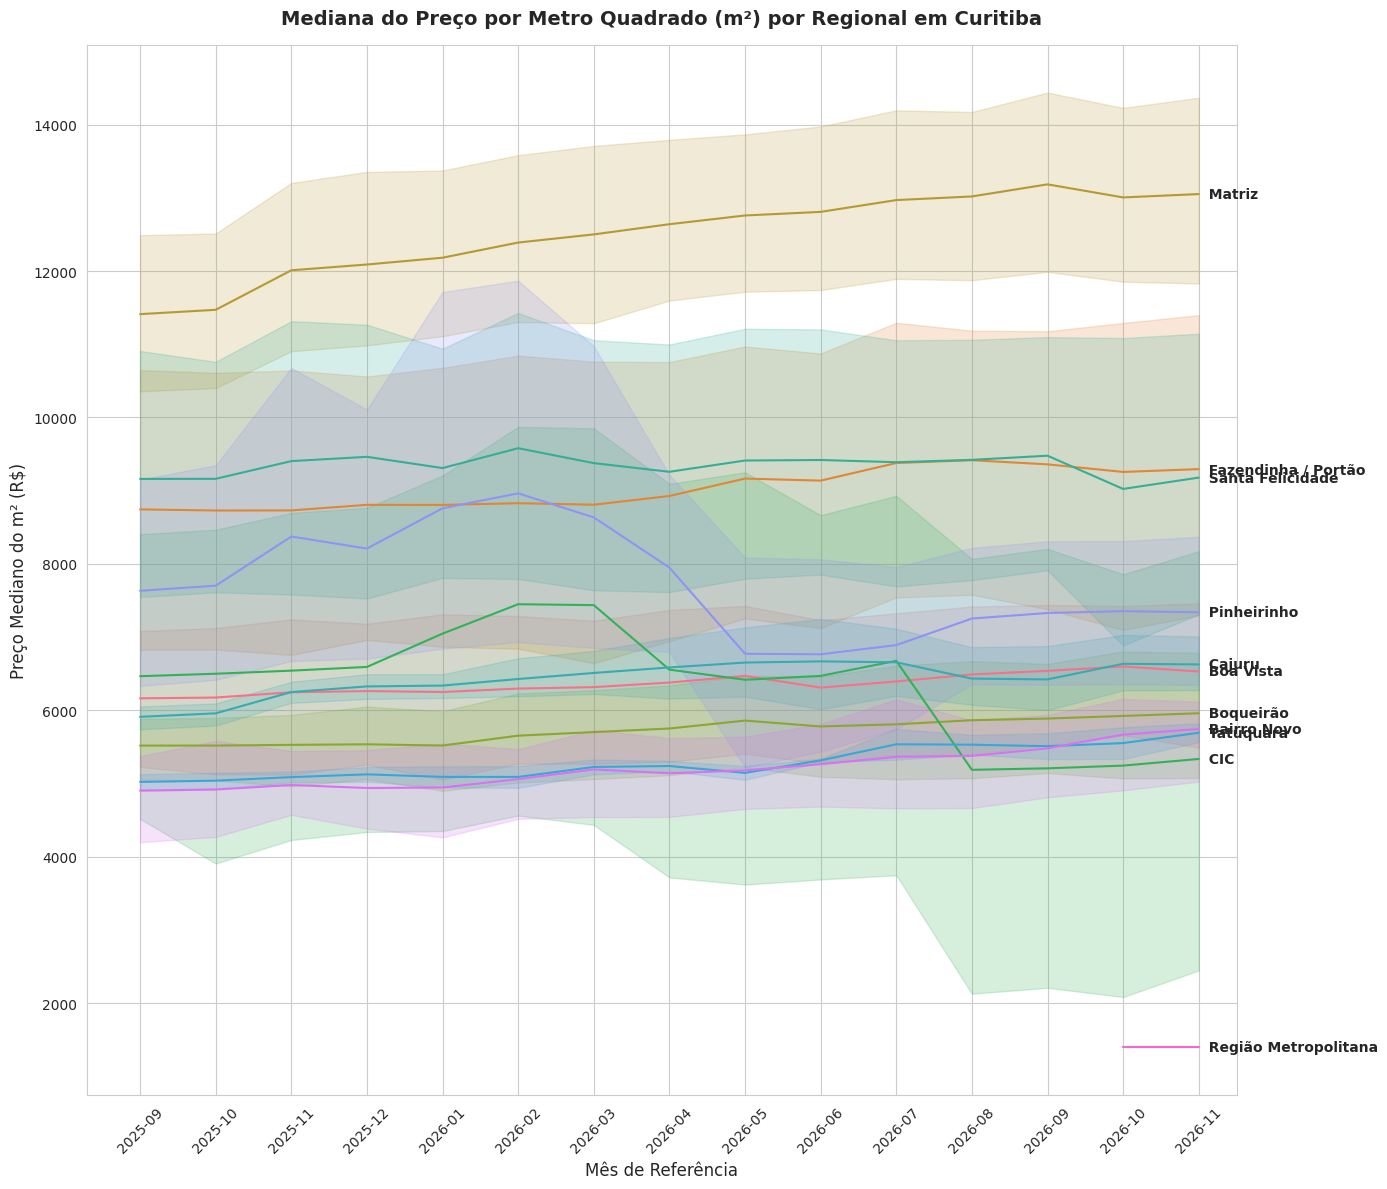

In [8]:

with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(14, 12))

  # Plotamos as linhas sem exibir a legenda padrão do seaborn (legend=False)
  sns.lineplot(
      data=imoveis_df,
      y='mediana_m2',
      x='mes',
      hue='regional',
      ax=ax,
      legend=False
  )

  # Configuração do título e eixos
  ax.set_title('Mediana do Preço por Metro Quadrado (m²) por Regional em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço Mediano do m² (R$)', fontsize=12)

  # Rotacionar as datas do eixo X para melhor leitura
  plt.xticks(rotation=45)

  # Adicionar o nome da regional diretamente no final de cada linha
  # Ordenamos os meses para garantir que pegamos o último ponto cronológico de forma consistente
  meses_ordenados = sorted(imoveis_df['mes'].unique())
  ultimo_mes = meses_ordenados[-1]

  # Iteramos sobre cada regional para posicionar o texto
  for regional, df_reg in imoveis_df.groupby('regional'):
      # Filtra os dados da regional para o último mês disponível dela
      df_ultimo = df_reg[df_reg['mes'] == ultimo_mes]
      if not df_ultimo.empty:
          y_val = df_ultimo['mediana_m2'].mean() # Caso haja múltiplos registros, tiramos a média
          # Adiciona o texto ligeiramente deslocado para a direita do último ponto do eixo X
          ax.text(
              x=ultimo_mes,
              y=y_val,
              s=f'  {regional}',
              va='center',
              fontsize=10,
              fontweight='semibold'
          )

  # Ajusta o limite do eixo X para dar espaço para o texto não ser cortado
  ax.set_xlim(right=len(meses_ordenados) - 0.5)

  plt.tight_layout()
  plt.show()

## Bairros com valores maiores e menores

       mes  mediana_m2
0  2026-11      8105.0


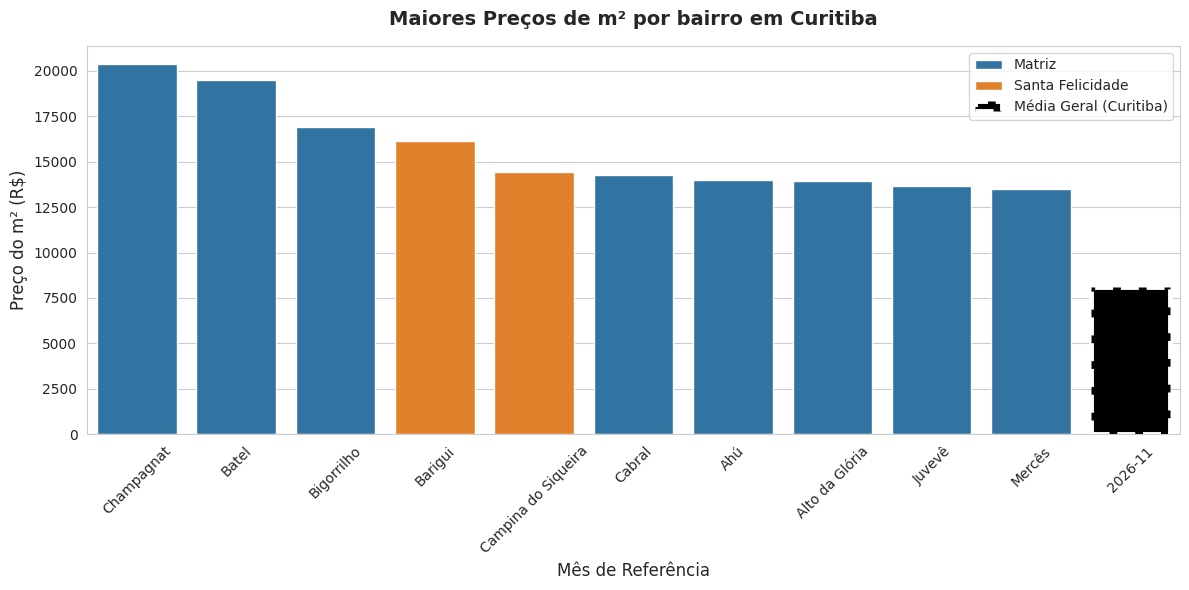

In [9]:
# Filtrar base com 10 maiores valores no último mês
ultimo_mes = imoveis_df.mes.max()
bairros_maiores = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].nlargest(10, 'mediana_m2')

# Plotar gráfico
with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(12, 6))
  sns.barplot(
      data=bairros_maiores,
      y='mediana_m2',
      x='bairro',
      hue='regional',
      ax=ax,
      legend=True
  )

  # adicionar mediana entre os bairros de imoveis_df no último mês
  mediana_geral = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].groupby('mes').agg({'mediana_m2': 'median'}).reset_index()
  print(mediana_geral)
  sns.barplot(
      data=mediana_geral,
      y='mediana_m2',
      x='mes',
      ax=ax,
      color='black',
      linewidth=3.5,
      linestyle='--',
      label='Média Geral (Curitiba)'
  )

  # Configuração do título e eixos

  ax.set_title('Maiores Preços de m² por bairro em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço do m² (R$)', fontsize=12)
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()


       mes  mediana_m2
0  2026-11      8105.0


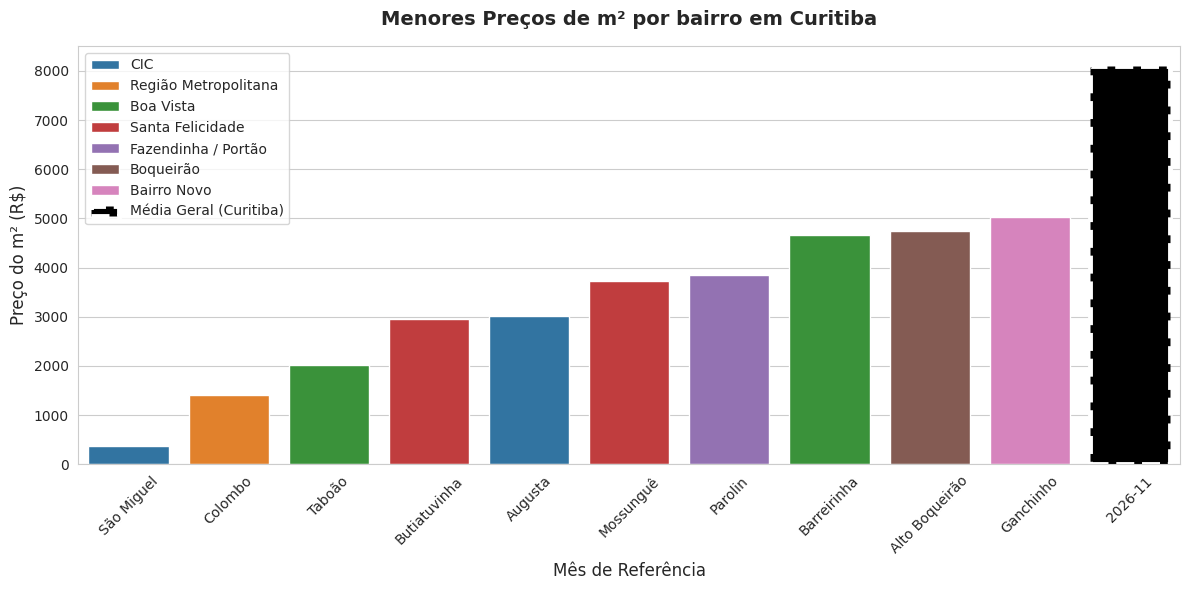

In [10]:
# Filtrar base com 10 menores valores no último mês
ultimo_mes = imoveis_df.mes.max()
bairros_menores = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].nsmallest(10, 'mediana_m2')

# Plotar gráfico
with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(12, 6))
  sns.barplot(
      data=bairros_menores,
      y='mediana_m2',
      x='bairro',
      hue='regional',
      ax=ax,
      legend=True
  )

  # adicionar mediana entre os bairros de imoveis_df no último mês
  mediana_geral = imoveis_df.loc[imoveis_df['mes'] == ultimo_mes].groupby('mes').agg({'mediana_m2': 'median'}).reset_index()
  print(mediana_geral)
  sns.barplot(
      data=mediana_geral,
      y='mediana_m2',
      x='mes',
      ax=ax,
      color='black',
      linewidth=3.5,
      linestyle='--',
      label='Média Geral (Curitiba)'
  )

  # Configuração do título e eixos

  ax.set_title('Menores Preços de m² por bairro em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço do m² (R$)', fontsize=12)
  plt.xticks(rotation=45)
  plt.tight_layout()
  plt.show()


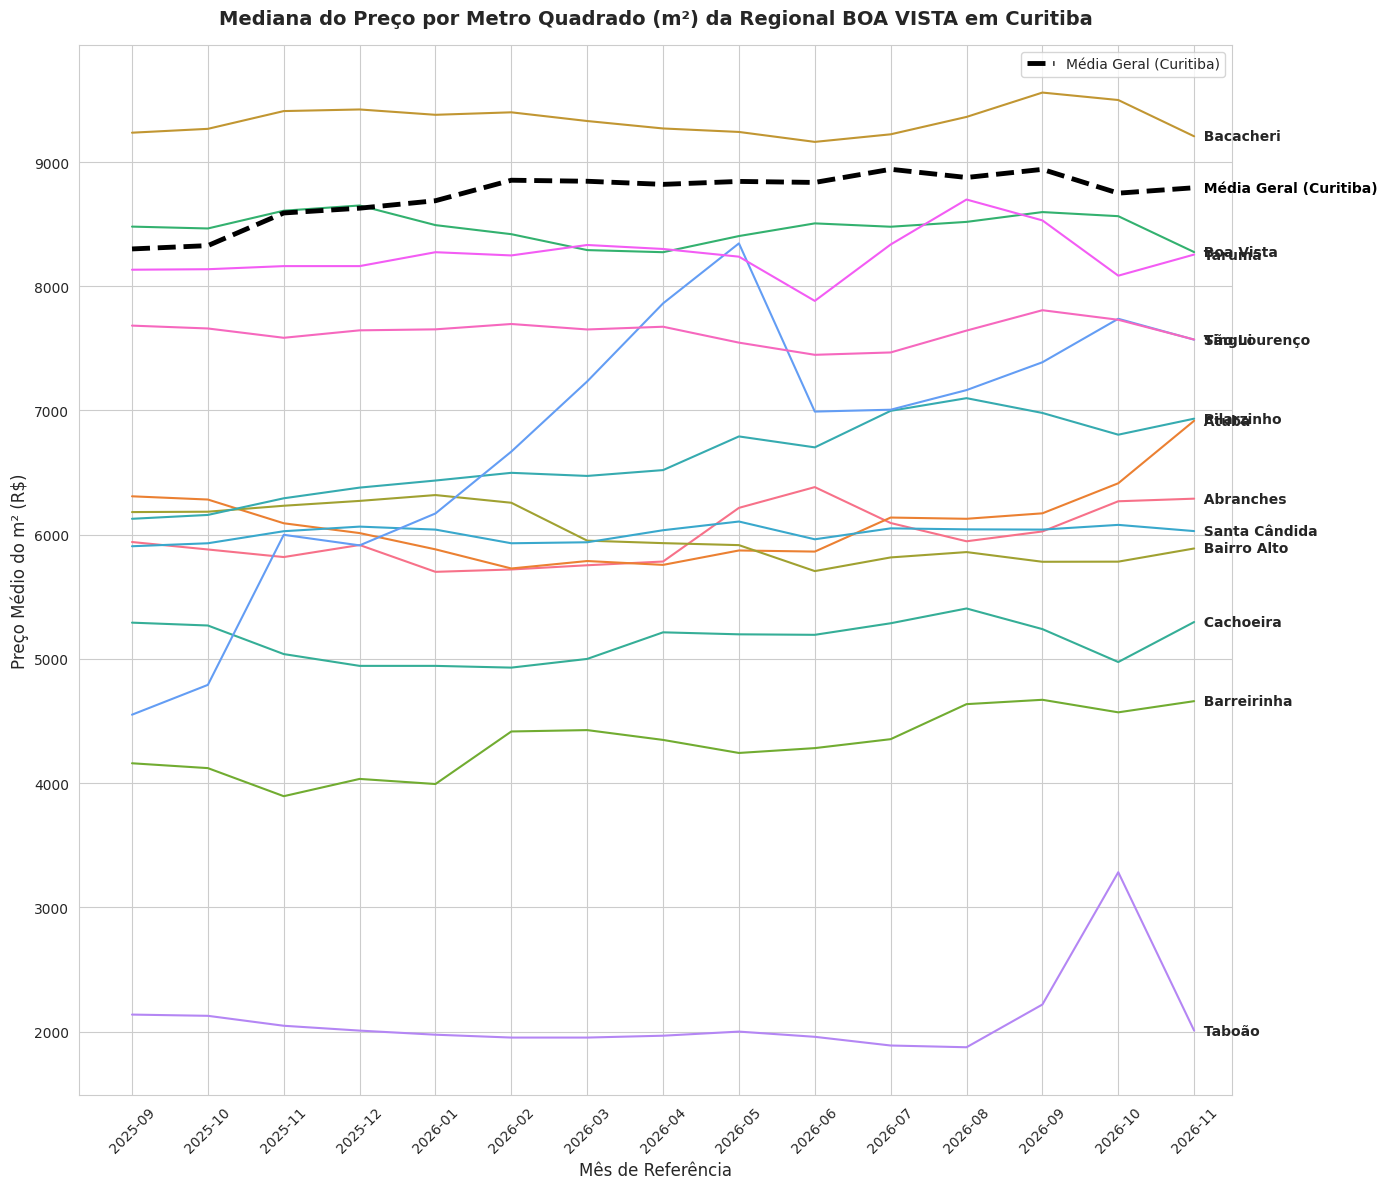

In [11]:
regional = 'Boa Vista' # @param ['Boa Vista', 'Matriz', 'Santa Felicidade', 'Cajuru', 'Boqueirão', 'Pinheirinho', 'Bairro Novo', 'Tatuquara', 'Fazendinha / Portão', 'CIC']

with sns.axes_style('whitegrid'):
  # Aumentamos um pouco a margem direita da figura para caberem os nomes dos bairros/regionais
  fig, ax = plt.subplots(figsize=(14, 12))

  # Filtramos usando imoveis_df['regional']
  df_filtrado = imoveis_df[imoveis_df['regional'] == regional]

  # Plotamos as linhas sem exibir a legenda padrão do seaborn (legend=False)
  sns.lineplot(
      data=df_filtrado,
      y='mediana_m2',
      x='mes',
      hue='bairro',
      ax=ax,
      legend=False
  )

  # Calcular e plotar a média geral de Curitiba (com base em todos os dados de venda do dataset)
  media_geral = imoveis_df.groupby('mes')['mediana_m2'].mean().reset_index()
  sns.lineplot(
      data=media_geral,
      y='mediana_m2',
      x='mes',
      ax=ax,
      color='black',
      linewidth=3.5,
      linestyle='--',
      label='Média Geral (Curitiba)'
  )

  # Configuração do título e eixos
  ax.set_title(f'Mediana do Preço por Metro Quadrado (m²) da Regional {regional.upper()} em Curitiba', fontsize=14, fontweight='bold', pad=15)
  ax.set_xlabel('Mês de Referência', fontsize=12)
  ax.set_ylabel('Preço Médio do m² (R$)', fontsize=12)

  # Rotacionar as datas do eixo X para melhor leitura
  plt.xticks(rotation=45)

  # Adicionar o nome do bairro diretamente no final de cada linha
  meses_ordenados = sorted(df_filtrado['mes'].unique())
  if meses_ordenados:
      ultimo_mes = meses_ordenados[-1]

      # Iteramos sobre cada bairro da regional filtrada
      for bairro, df_bairro in df_filtrado.groupby('bairro'):
          # Filtra os dados do bairro para o último mês disponível dele
          df_ultimo = df_bairro[df_bairro['mes'] == ultimo_mes]
          if not df_ultimo.empty:
              y_val = df_ultimo['mediana_m2'].mean()
              # Adiciona o nome do bairro real ao final da linha correspondente
              ax.text(
                  x=ultimo_mes,
                  y=y_val,
                  s=f'  {bairro}',
                  va='center',
                  fontsize=10,
                  fontweight='semibold'
              )

      # Adicionar o rótulo da linha de média geral ao final dela
      df_ultimo_geral = media_geral[media_geral['mes'] == ultimo_mes]
      if not df_ultimo_geral.empty:
          y_val_geral = df_ultimo_geral['mediana_m2'].mean()
          ax.text(
              x=ultimo_mes,
              y=y_val_geral,
              s='  Média Geral (Curitiba)',
              va='center',
              fontsize=10,
              fontweight='bold',
              color='black'
          )

      # Ajusta o limite do eixo X para dar espaço para o texto não ser cortado
      ax.set_xlim(right=len(meses_ordenados) - 0.5)

  plt.tight_layout()
  plt.show()

# Mostrar anúncios ativos